<a href="https://colab.research.google.com/github/Csahoo009/ML-for-DA/blob/main/T8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from google.colab import files

# Load dataset directly from uploaded CSV
uploaded = files.upload()

# 1. Load dataset
df = pd.read_csv('indian_house_prices.csv')

# 2. Scale Price to ₹ Lakhs for readability
df["Price_Lakhs"] = df["Price"] / 100000.0

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(df[["Area", "Price_Lakhs", "No. of Bedrooms", "Gymnasium", "Resale"]].head())

Saving indian_house_prices.csv to indian_house_prices.csv
Dataset Shape: 32963 rows, 42 columns
   Area  Price_Lakhs  No. of Bedrooms  Gymnasium  Resale
0  3340       300.00                4          1       0
1  1045        78.88                2          1       0
2  1179        48.66                2          1       0
3  1675        83.58                3          0       0
4  1670        68.45                3          1       0


In [ ]:
# Select predictors and binary target ('Resale': 0 = New, 1 = Resale)
features = [
    'Area', 'Price_Lakhs', 'No. of Bedrooms',
    'Gymnasium', 'SwimmingPool', 'LiftAvailable', '24X7Security'
]
target = 'Resale'

X = df[features].fillna(df[features].mean())
y = df[target]

# Stratified split to maintain class balance (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training Samples: {len(X_train)}")
print(f"Testing Samples : {len(X_test)}")

Training Samples: 26370
Testing Samples : 6593


In [ ]:
# Initialize and train Gaussian Naïve Bayes model
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# Inspect Class Prior Probabilities P(Y)
print("=== Naïve Bayes Model Trained ===")
print(f"Prior Probability P(New - 0)   : {nb_model.class_prior_[0]:.4f}")
print(f"Prior Probability P(Resale - 1): {nb_model.class_prior_[1]:.4f}")

=== Naïve Bayes Model Trained ===
Prior Probability P(New - 0)   : 0.6186
Prior Probability P(Resale - 1): 0.3814


In [ ]:
# Predict class labels and probabilities
y_pred_nb = nb_model.predict(X_test)
y_prob_nb = nb_model.predict_proba(X_test)

# Calculate Evaluation Metrics
acc = accuracy_score(y_test, y_pred_nb)
prec = precision_score(y_test, y_pred_nb, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred_nb, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred_nb, average='weighted', zero_division=0)
cm = confusion_matrix(y_test, y_pred_nb)

print("=== T8: NAÏVE BAYES PERFORMANCE METRICS ===")
print(f"Accuracy  : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}\n")

print("Confusion Matrix:")
print(cm)

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_nb, target_names=["New (0)", "Resale (1)"], zero_division=0))

=== T8: NAÏVE BAYES PERFORMANCE METRICS ===
Accuracy  : 0.6340 (63.40%)
Precision : 0.6128
Recall    : 0.6340
F1-Score  : 0.5733

Confusion Matrix:
[[3713  365]
 [2048  467]]

Detailed Classification Report:
              precision    recall  f1-score   support

     New (0)       0.64      0.91      0.75      4078
  Resale (1)       0.56      0.19      0.28      2515

    accuracy                           0.63      6593
   macro avg       0.60      0.55      0.52      6593
weighted avg       0.61      0.63      0.57      6593



5-Fold CV Accuracy Scores: [0.6402 0.6384 0.6339 0.645  0.635 ]
Mean CV Accuracy         : 0.6385



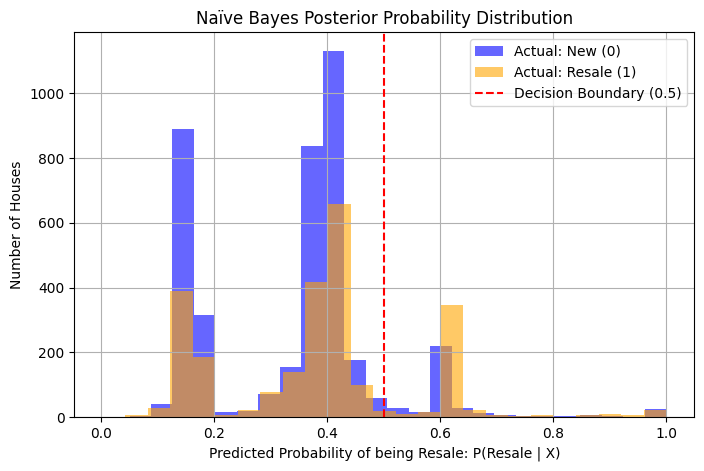

In [ ]:
# 1. 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(nb_model, X, y, cv=cv, scoring='accuracy')

print(f"5-Fold CV Accuracy Scores: {np.round(cv_scores, 4)}")
print(f"Mean CV Accuracy         : {cv_scores.mean():.4f}\n")

# 2. Predicted Posterior Probabilities Distribution Plot
plt.figure(figsize=(8, 5))
plt.hist(y_prob_nb[y_test == 0, 1], bins=25, alpha=0.6, label="Actual: New (0)", color='blue')
plt.hist(y_prob_nb[y_test == 1, 1], bins=25, alpha=0.6, label="Actual: Resale (1)", color='orange')
plt.axvline(0.5, color='red', linestyle='--', label='Decision Boundary (0.5)')

plt.xlabel("Predicted Probability of being Resale: P(Resale | X)")
plt.ylabel("Number of Houses")
plt.title("Naïve Bayes Posterior Probability Distribution")
plt.legend()
plt.grid(True)
plt.show()